In [1]:
# Assignment 2 - Part A Object Recognition Implementation
# Dataset: CUB-200-2011
# Task: Compare classical and deep learning methods for bird species recognition
# Deep Learning Approach:
# Experiment 2 = Whole image + MobileNetV2 transfer learning
# Experiment 4 = Bounding box crop + MobileNetV2 transfer learning
# Cell 1: Imports and setup

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# ---------------------------------------------------------
# Reproducibility settings
# ---------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ---------------------------------------------------------
# Dataset and output paths
# ---------------------------------------------------------
# The notebook should be placed inside the CUB_200_2011 folder.
# Therefore, DATASET_DIR is set to ".".

DATASET_DIR = os.path.join("data", "CUB_200_2011")  # see README for download
IMAGE_DIR = os.path.join(DATASET_DIR, "images")
OUTPUT_DIR = "outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------------------------------------------------
# Deep learning settings
# ---------------------------------------------------------
# MobileNetV2 expects 224x224 RGB images.
# 200 output classes are required because CUB-200-2011 has 200 bird species.

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 200

# ---------------------------------------------------------
# Check TensorFlow and GPU
# ---------------------------------------------------------

print("TensorFlow version:", tf.__version__)
print("Dataset folder:", os.path.abspath(DATASET_DIR))
print("Images folder exists:", os.path.exists(IMAGE_DIR))
print("Output folder:", os.path.abspath(OUTPUT_DIR))

gpus = tf.config.list_physical_devices("GPU")
print("GPUs available:", gpus)

# Allow TensorFlow to use GPU memory gradually if a GPU is available
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except:
        pass

TensorFlow version: 2.20.0
Dataset folder: data/CUB_200_2011
Images folder exists: True
Output folder: outputs
GPUs available: []


In [2]:
# Cell 2: Load CUB-200-2011 metadata
# This cell reads the image paths, class labels, class names,
# bounding boxes, and official train/test split.

def find_file(possible_names):
    """
    Finds the first existing file from a list of possible file names.
    This is useful because some extracted CUB files may not include the .txt extension.
    """
    for name in possible_names:
        path = os.path.join(DATASET_DIR, name)
        if os.path.isfile(path):
            return path
    
    raise FileNotFoundError(f"Could not find any of these files: {possible_names}")


# Find metadata files
images_file = find_file(["images.txt", "images"])
labels_file = find_file(["image_class_labels.txt", "image_class_labels"])
classes_file = find_file(["classes.txt", "classes"])
bboxes_file = find_file(["bounding_boxes.txt", "bounding_boxes"])
split_file = find_file(["train_test_split.txt", "train_test_split"])

print("Images metadata file:", images_file)
print("Labels file:", labels_file)
print("Classes file:", classes_file)
print("Bounding boxes file:", bboxes_file)
print("Train/test split file:", split_file)


# Read metadata files
images_df = pd.read_csv(
    images_file,
    sep=r"\s+",
    names=["image_id", "image_path"]
)

labels_df = pd.read_csv(
    labels_file,
    sep=r"\s+",
    names=["image_id", "class_id"]
)

classes_df = pd.read_csv(
    classes_file,
    sep=r"\s+",
    names=["class_id", "class_name"]
)

bboxes_df = pd.read_csv(
    bboxes_file,
    sep=r"\s+",
    names=["image_id", "x", "y", "width", "height"]
)

split_df = pd.read_csv(
    split_file,
    sep=r"\s+",
    names=["image_id", "is_train"]
)


# Merge all metadata into one dataframe
metadata = images_df.merge(labels_df, on="image_id")
metadata = metadata.merge(classes_df, on="class_id")
metadata = metadata.merge(bboxes_df, on="image_id")
metadata = metadata.merge(split_df, on="image_id")

# Full image path
metadata["full_path"] = metadata["image_path"].apply(
    lambda p: os.path.join(IMAGE_DIR, p)
)

# Deep learning labels must start from 0 rather than 1
# Original class_id: 1 to 200
# New label: 0 to 199
metadata["label"] = metadata["class_id"] - 1

# Check file existence
metadata["file_exists"] = metadata["full_path"].apply(os.path.exists)

print("\nMetadata preview:")
display(metadata.head())

print("Total images:", len(metadata))
print("Number of classes:", metadata["class_id"].nunique())
print("Training images:", metadata["is_train"].sum())
print("Testing images:", (metadata["is_train"] == 0).sum())
print("All image files exist:", metadata["file_exists"].all())

if not metadata["file_exists"].all():
    missing = metadata[metadata["file_exists"] == False]
    print("Missing files:")
    display(missing.head())

Images metadata file: .\images.txt
Labels file: .\image_class_labels.txt
Classes file: .\classes.txt
Bounding boxes file: .\bounding_boxes.txt
Train/test split file: .\train_test_split.txt

Metadata preview:


,image_id,image_path,class_id,class_name,x,y,width,height,is_train,full_path,label,file_exists
0,1,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,60.0,27.0,325.0,304.0,0,.\images\001.Black_footed_Albatross/Black_Foot...,0,True
1,2,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,139.0,30.0,153.0,264.0,1,.\images\001.Black_footed_Albatross/Black_Foot...,0,True
2,3,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,14.0,112.0,388.0,186.0,0,.\images\001.Black_footed_Albatross/Black_Foot...,0,True
3,4,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,112.0,90.0,255.0,242.0,1,.\images\001.Black_footed_Albatross/Black_Foot...,0,True
4,5,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,70.0,50.0,134.0,303.0,1,.\images\001.Black_footed_Albatross/Black_Foot...,0,True


Total images: 11788
Number of classes: 200
Training images: 5994
Testing images: 5794
All image files exist: True


In [3]:
# Cell 3: Create train, validation, and test sets
# The assignment requires using the official train/test split.
# A validation set is created only from the training set for tuning and early stopping.

# Official training and testing data
train_full_df = metadata[metadata["is_train"] == 1].reset_index(drop=True)
test_df = metadata[metadata["is_train"] == 0].reset_index(drop=True)

# Create validation set from the official training set
# Stratify keeps all 200 bird classes balanced across train and validation sets.
train_df, val_df = train_test_split(
    train_full_df,
    test_size=0.15,
    random_state=SEED,
    stratify=train_full_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nNumber of classes:")
print("Training classes:", train_df["label"].nunique())
print("Validation classes:", val_df["label"].nunique())
print("Testing classes:", test_df["label"].nunique())

# Quick class distribution check
split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Testing"],
    "Images": [len(train_df), len(val_df), len(test_df)],
    "Classes": [
        train_df["label"].nunique(),
        val_df["label"].nunique(),
        test_df["label"].nunique()
    ]
})

display(split_summary)

# Save split summary for report/reference
split_summary.to_csv(
    os.path.join(OUTPUT_DIR, "deep_learning_split_summary.csv"),
    index=False
)

print("Saved split summary to outputs/deep_learning_split_summary.csv")


Training images: 5094
Validation images: 900
Testing images: 5794

Number of classes:
Training classes: 200
Validation classes: 200
Testing classes: 200


,Split,Images,Classes
0,Training,5094,200
1,Validation,900,200
2,Testing,5794,200


Saved split summary to outputs/deep_learning_split_summary.csv


In [5]:
# Cell 4: Image loading and preprocessing functions
# These functions create the two required deep learning input settings:
# 1. Whole image input for Experiment 2
# 2. Bounding box crop input for Experiment 4

def load_and_preprocess_whole(path, label):
    """
    Load a whole image, resize it to 224x224, and apply MobileNetV2 preprocessing.

    This is used for:
    Experiment 2: Deep learning using whole images.
    """
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)

    return image, label


def load_and_preprocess_bbox(path, label, x, y, width, height):
    """
    Load an image, crop the bird region using the provided bounding box,
    resize the crop to 224x224, and apply MobileNetV2 preprocessing.

    This is used for:
    Experiment 4: Deep learning using bounding box crops.
    """
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)

    # Get image size
    img_shape = tf.shape(image)
    img_h = tf.cast(img_shape[0], tf.float32)
    img_w = tf.cast(img_shape[1], tf.float32)

    # Convert bounding box values to float
    x = tf.cast(x, tf.float32)
    y = tf.cast(y, tf.float32)
    width = tf.cast(width, tf.float32)
    height = tf.cast(height, tf.float32)

    # Make sure the crop stays inside image boundaries
    x1 = tf.clip_by_value(x, 0, img_w - 1)
    y1 = tf.clip_by_value(y, 0, img_h - 1)
    x2 = tf.clip_by_value(x + width, 1, img_w)
    y2 = tf.clip_by_value(y + height, 1, img_h)

    crop_width = tf.cast(x2 - x1, tf.int32)
    crop_height = tf.cast(y2 - y1, tf.int32)

    # Crop bird area
    image = tf.image.crop_to_bounding_box(
        image,
        offset_height=tf.cast(y1, tf.int32),
        offset_width=tf.cast(x1, tf.int32),
        target_height=crop_height,
        target_width=crop_width
    )

    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)

    return image, label

In [6]:
# Cell 5: Build TensorFlow datasets
# This creates efficient tf.data pipelines for both deep learning experiments.

def make_whole_dataset(df, shuffle=False):
    """
    Create a TensorFlow dataset for whole-image input.
    """
    paths = df["full_path"].values
    labels = df["label"].values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=SEED)

    ds = ds.map(load_and_preprocess_whole, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


def make_bbox_dataset(df, shuffle=False):
    """
    Create a TensorFlow dataset for bounding-box crop input.
    """
    paths = df["full_path"].values
    labels = df["label"].values.astype(np.int32)

    x = df["x"].values.astype(np.float32)
    y = df["y"].values.astype(np.float32)
    width = df["width"].values.astype(np.float32)
    height = df["height"].values.astype(np.float32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels, x, y, width, height))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=SEED)

    ds = ds.map(load_and_preprocess_bbox, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


# Experiment 2 datasets: whole image input
train_whole_ds = make_whole_dataset(train_df, shuffle=True)
val_whole_ds = make_whole_dataset(val_df, shuffle=False)
test_whole_ds = make_whole_dataset(test_df, shuffle=False)

# Experiment 4 datasets: bounding box crop input
train_bbox_ds = make_bbox_dataset(train_df, shuffle=True)
val_bbox_ds = make_bbox_dataset(val_df, shuffle=False)
test_bbox_ds = make_bbox_dataset(test_df, shuffle=False)

print("TensorFlow datasets created successfully.")

print("Experiment 2 whole-image datasets:")
print(train_whole_ds)
print(val_whole_ds)
print(test_whole_ds)

print("\nExperiment 4 bounding-box datasets:")
print(train_bbox_ds)
print(val_bbox_ds)
print(test_bbox_ds)

TensorFlow datasets created successfully.
Experiment 2 whole-image datasets:
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

Experiment 4 bounding-box datasets:
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(

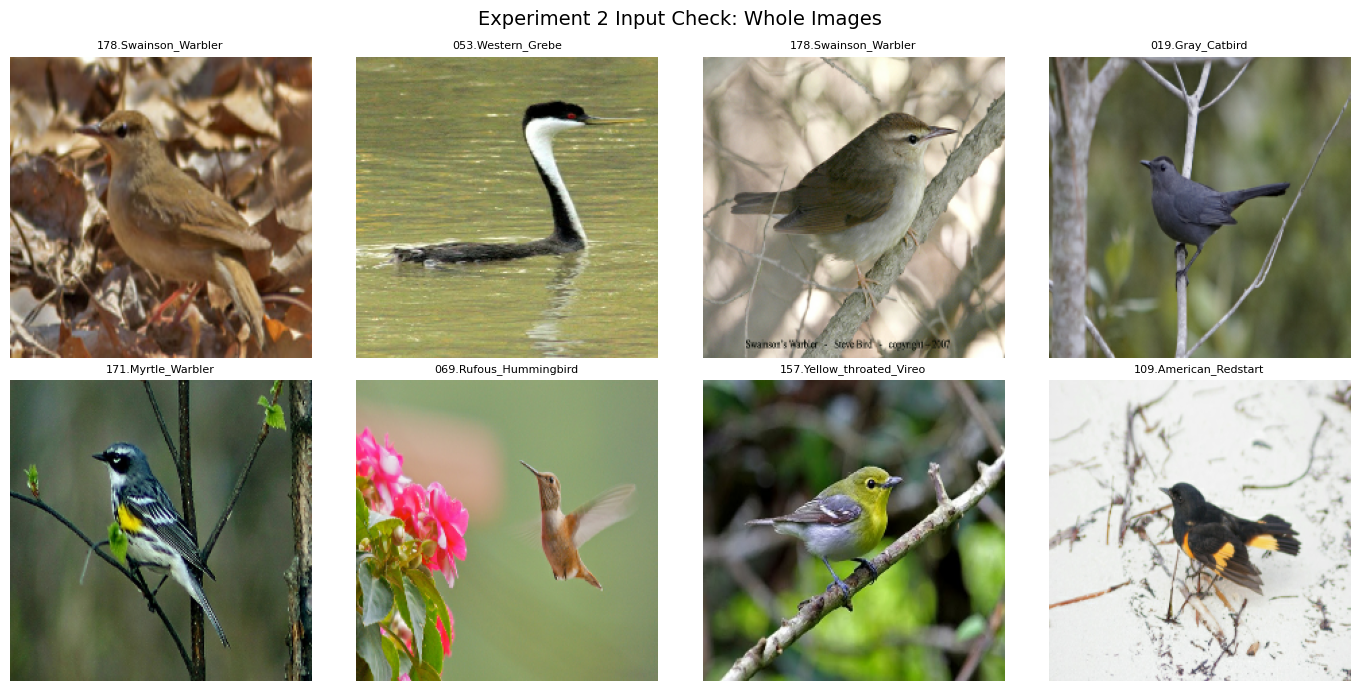

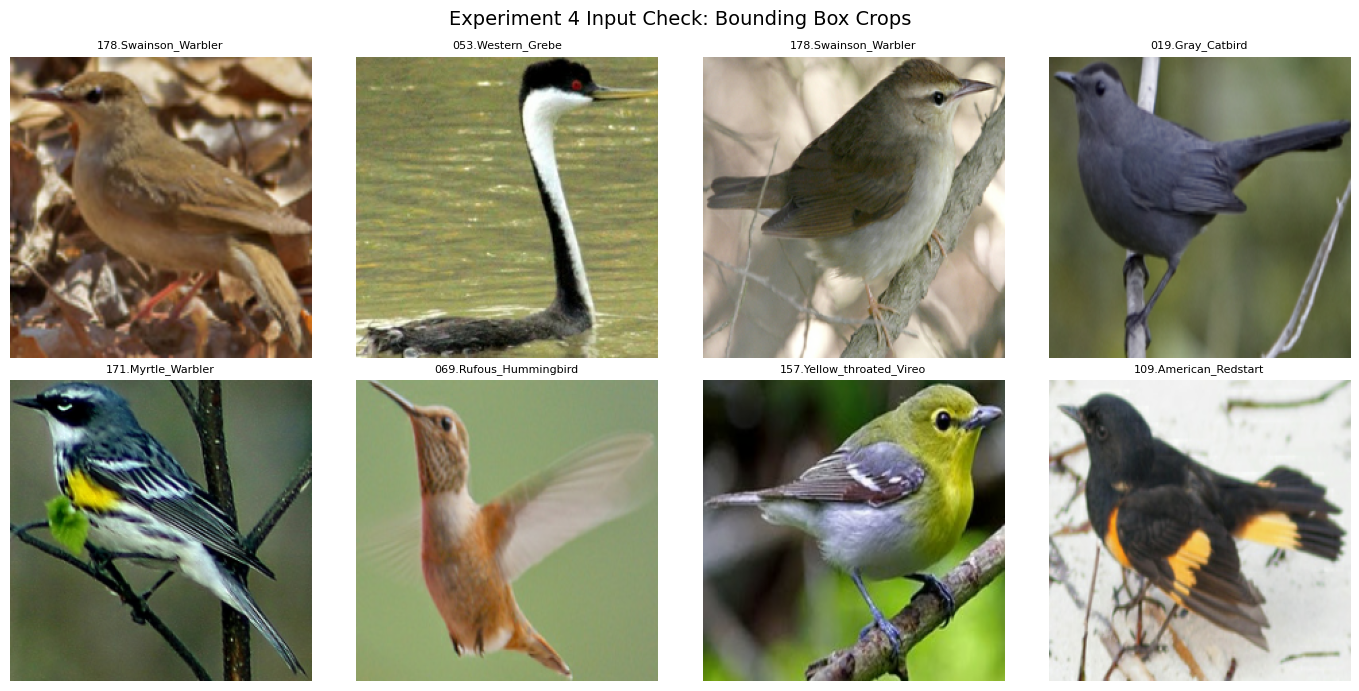

In [7]:
# Cell 6: Visual check of deep learning input pipelines
# This confirms that whole-image and bounding-box crop inputs are loading correctly.

def reverse_mobilenet_preprocess(image):
    """
    MobileNetV2 preprocess_input scales images to [-1, 1].
    This function converts them back to [0, 1] for display.
    """
    image = (image + 1.0) / 2.0
    image = np.clip(image, 0, 1)
    return image


def show_batch(dataset, title, num_images=8):
    """
    Display a small batch of images from a TensorFlow dataset.
    """
    images, labels = next(iter(dataset))

    plt.figure(figsize=(14, 7))

    for i in range(num_images):
        ax = plt.subplot(2, 4, i + 1)

        img = images[i].numpy()
        img = reverse_mobilenet_preprocess(img)

        class_id = int(labels[i].numpy()) + 1
        class_name = metadata[metadata["class_id"] == class_id]["class_name"].iloc[0]

        plt.imshow(img)
        plt.title(class_name[:28], fontsize=8)
        plt.axis("off")

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


show_batch(train_whole_ds, "Experiment 2 Input Check: Whole Images")
show_batch(train_bbox_ds, "Experiment 4 Input Check: Bounding Box Crops")

In [8]:
# Cell 7: Build MobileNetV2 transfer learning model
# This model is used for the deep learning approach.
# MobileNetV2 learns image features automatically, unlike HOG.

def build_mobilenetv2_model(num_classes=NUM_CLASSES, input_shape=(224, 224, 3)):
    """
    Build a transfer learning model using MobileNetV2.

    Method:
    - Pretrained MobileNetV2 is used as the feature extractor.
    - The ImageNet weights are reused to improve learning on the smaller CUB dataset.
    - A new classification head is added for the 200 bird species.
    """

    # Data augmentation is used only during training.
    # It helps reduce overfitting because each bird class has limited images.
    data_augmentation = tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.10),
    ], name="data_augmentation")

    # Pretrained MobileNetV2 backbone
    base_model = MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape
    )

    # Freeze pretrained layers for the first training stage
    base_model.trainable = False

    inputs = layers.Input(shape=input_shape)

    x = data_augmentation(inputs)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model, base_model


# Build model for Experiment 2
model_exp2, base_model_exp2 = build_mobilenetv2_model()

model_exp2.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 200)            │        51,400 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,637,320 (10.06 MB)

 Trainable params: 379,336 (1.45 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
# Cell 8: Train Experiment 2
# Experiment 2 = Deep learning using whole images

EPOCHS_STAGE1 = 10

exp2_model_path = os.path.join(OUTPUT_DIR, "exp2_mobilenetv2_whole_image_best.keras")

callbacks_exp2 = [
    ModelCheckpoint(
        exp2_model_path,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        restore_best_weights=True,
        mode="max",
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("=" * 80)
print("Training Experiment 2: MobileNetV2 Transfer Learning using Whole Images")
print("=" * 80)

history_exp2 = model_exp2.fit(
    train_whole_ds,
    validation_data=val_whole_ds,
    epochs=EPOCHS_STAGE1,
    callbacks=callbacks_exp2
)

print("Experiment 2 training complete.")
print("Best model saved to:", exp2_model_path)

Training Experiment 2: MobileNetV2 Transfer Learning using Whole Images
Epoch 1/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 871ms/step - accuracy: 0.0278 - loss: 5.1960      
Epoch 1: val_accuracy improved from None to 0.21778, saving model to .\outputs\exp2_mobilenetv2_whole_image_best.keras
160/160 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step - accuracy: 0.0609 - loss: 4.7776 - val_accuracy: 0.2178 - val_loss: 3.4037 - learning_rate: 0.0010
Epoch 2/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 913ms/step - accuracy: 0.1998 - loss: 3.3678  
Epoch 2: val_accuracy improved from 0.21778 to 0.35889, saving model to .\outputs\exp2_mobilenetv2_whole_image_best.keras
160/160 ━━━━━━━━━━━━━━━━━━━━ 169s 1s/step - accuracy: 0.2307 - loss: 3.1699 - val_accuracy: 0.3589 - val_loss: 2.4785 - learning_rate: 0.0010
Epoch 3/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 873ms/step - accuracy: 0.3238 - loss: 2.6175  
Epoch 3: val_accuracy improved from 0.35889 to 0.42333, saving model to .\outputs\exp2_mobilenetv2_whole_image_best.keras
160/160

In [10]:
# Cell 9: Evaluate Experiment 2 on the official test set
# Required metric: overall classification accuracy and class-wise accuracy.

print("=" * 80)
print("Evaluating Experiment 2: Whole Image Deep Learning")
print("=" * 80)

# Load best saved model
best_model_exp2 = tf.keras.models.load_model(exp2_model_path)

# Evaluate on official test set
test_loss_exp2, test_acc_exp2 = best_model_exp2.evaluate(test_whole_ds)

print(f"Experiment 2 test loss: {test_loss_exp2:.4f}")
print(f"Experiment 2 overall test accuracy: {test_acc_exp2:.4f}")
print(f"Experiment 2 overall test accuracy percentage: {test_acc_exp2 * 100:.2f}%")

# Predict labels for class-wise accuracy
y_true_exp2 = test_df["label"].values
y_prob_exp2 = best_model_exp2.predict(test_whole_ds)
y_pred_exp2 = np.argmax(y_prob_exp2, axis=1)

# Save overall result
deep_exp2_results = pd.DataFrame({
    "Experiment": ["Experiment 2"],
    "Method": ["MobileNetV2 Transfer Learning"],
    "Input Type": ["Whole Image"],
    "Accuracy": [test_acc_exp2],
    "Accuracy (%)": [test_acc_exp2 * 100],
    "Test Loss": [test_loss_exp2]
})

display(deep_exp2_results)

deep_exp2_results.to_csv(
    os.path.join(OUTPUT_DIR, "deep_learning_exp2_overall_results.csv"),
    index=False
)

# ---------------------------------------------------------
# Class-wise accuracy
# ---------------------------------------------------------

def compute_classwise_accuracy_deep(y_true, y_pred, df, experiment_name):
    """
    Compute class-wise accuracy for deep learning experiments.
    Labels are 0 to 199, while class_id is 1 to 200.
    """
    results = []

    for label in sorted(np.unique(y_true)):
        class_indices = np.where(y_true == label)[0]

        total_images = len(class_indices)
        correct_predictions = np.sum(y_pred[class_indices] == y_true[class_indices])
        class_accuracy = correct_predictions / total_images if total_images > 0 else 0

        class_id = label + 1
        class_name = df[df["class_id"] == class_id]["class_name"].iloc[0]

        results.append({
            "experiment": experiment_name,
            "class_id": class_id,
            "class_name": class_name,
            "test_images": total_images,
            "correct_predictions": correct_predictions,
            "class_accuracy": class_accuracy,
            "class_accuracy_percent": class_accuracy * 100
        })

    return pd.DataFrame(results)


classwise_exp2 = compute_classwise_accuracy_deep(
    y_true_exp2,
    y_pred_exp2,
    test_df,
    "Experiment 2: Whole Image MobileNetV2"
)

print("Experiment 2 class-wise accuracy:")
display(classwise_exp2.head(10))

classwise_exp2.to_csv(
    os.path.join(OUTPUT_DIR, "classwise_accuracy_exp2_mobilenetv2_whole.csv"),
    index=False
)

print("Saved Experiment 2 overall and class-wise results.")

Evaluating Experiment 2: Whole Image Deep Learning
182/182 ━━━━━━━━━━━━━━━━━━━━ 140s 744ms/step - accuracy: 0.5373 - loss: 1.6740
Experiment 2 test loss: 1.6740
Experiment 2 overall test accuracy: 0.5373
Experiment 2 overall test accuracy percentage: 53.73%
182/182 ━━━━━━━━━━━━━━━━━━━━ 140s 756ms/step


,Experiment,Method,Input Type,Accuracy,Accuracy (%),Test Loss
0,Experiment 2,MobileNetV2 Transfer Learning,Whole Image,0.53728,53.727996,1.674027


Experiment 2 class-wise accuracy:


,experiment,class_id,class_name,test_images,correct_predictions,class_accuracy,class_accuracy_percent
0,Experiment 2: Whole Image MobileNetV2,1,001.Black_footed_Albatross,30,18,0.600000,60.000000
1,Experiment 2: Whole Image MobileNetV2,2,002.Laysan_Albatross,30,25,0.833333,83.333333
2,Experiment 2: Whole Image MobileNetV2,3,003.Sooty_Albatross,28,15,0.535714,53.571429
3,Experiment 2: Whole Image MobileNetV2,4,004.Groove_billed_Ani,30,22,0.733333,73.333333
4,Experiment 2: Whole Image MobileNetV2,5,005.Crested_Auklet,14,10,0.714286,71.428571
5,Experiment 2: Whole Image MobileNetV2,6,006.Least_Auklet,11,8,0.727273,72.727273
6,Experiment 2: Whole Image MobileNetV2,7,007.Parakeet_Auklet,23,16,0.695652,69.565217
7,Experiment 2: Whole Image MobileNetV2,8,008.Rhinoceros_Auklet,18,10,0.555556,55.555556
8,Experiment 2: Whole Image MobileNetV2,9,009.Brewer_Blackbird,29,4,0.137931,13.793103
9,Experiment 2: Whole Image MobileNetV2,10,010.Red_winged_Blackbird,30,23,0.766667,76.666667


Saved Experiment 2 overall and class-wise results.


In [11]:
# Cell 10: Build MobileNetV2 model for Experiment 4
# Experiment 4 = Deep learning using bounding box crops

model_exp4, base_model_exp4 = build_mobilenetv2_model()

model_exp4.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 200)            │        51,400 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,637,320 (10.06 MB)

 Trainable params: 379,336 (1.45 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [12]:
# Cell 11: Train Experiment 4
# Experiment 4 = MobileNetV2 transfer learning using bounding box crops

EPOCHS_STAGE1 = 10

exp4_model_path = os.path.join(OUTPUT_DIR, "exp4_mobilenetv2_bbox_best.keras")

callbacks_exp4 = [
    ModelCheckpoint(
        exp4_model_path,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        restore_best_weights=True,
        mode="max",
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("=" * 80)
print("Training Experiment 4: MobileNetV2 Transfer Learning using Bounding Box Crops")
print("=" * 80)

history_exp4 = model_exp4.fit(
    train_bbox_ds,
    validation_data=val_bbox_ds,
    epochs=EPOCHS_STAGE1,
    callbacks=callbacks_exp4
)

print("Experiment 4 training complete.")
print("Best model saved to:", exp4_model_path)

Training Experiment 4: MobileNetV2 Transfer Learning using Bounding Box Crops
Epoch 1/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 870ms/step - accuracy: 0.0314 - loss: 5.1420  
Epoch 1: val_accuracy improved from None to 0.24222, saving model to .\outputs\exp4_mobilenetv2_bbox_best.keras
160/160 ━━━━━━━━━━━━━━━━━━━━ 175s 1s/step - accuracy: 0.0662 - loss: 4.6880 - val_accuracy: 0.2422 - val_loss: 3.2763 - learning_rate: 0.0010
Epoch 2/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 863ms/step - accuracy: 0.2317 - loss: 3.2606  
Epoch 2: val_accuracy improved from 0.24222 to 0.39444, saving model to .\outputs\exp4_mobilenetv2_bbox_best.keras
160/160 ━━━━━━━━━━━━━━━━━━━━ 161s 1s/step - accuracy: 0.2564 - loss: 3.0538 - val_accuracy: 0.3944 - val_loss: 2.3106 - learning_rate: 0.0010
Epoch 3/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 863ms/step - accuracy: 0.3528 - loss: 2.4792  
Epoch 3: val_accuracy improved from 0.39444 to 0.49889, saving model to .\outputs\exp4_mobilenetv2_bbox_best.keras
160/160 ━━━━━━━━━━━━━━━━━━

In [13]:
# Cell 12: Evaluate Experiment 4 on the official test set
# Required metric: overall classification accuracy and class-wise accuracy.

print("=" * 80)
print("Evaluating Experiment 4: Bounding Box Deep Learning")
print("=" * 80)

# Load best saved model
best_model_exp4 = tf.keras.models.load_model(exp4_model_path)

# Evaluate on official test set
test_loss_exp4, test_acc_exp4 = best_model_exp4.evaluate(test_bbox_ds)

print(f"Experiment 4 test loss: {test_loss_exp4:.4f}")
print(f"Experiment 4 overall test accuracy: {test_acc_exp4:.4f}")
print(f"Experiment 4 overall test accuracy percentage: {test_acc_exp4 * 100:.2f}%")

# Predict labels for class-wise accuracy
y_true_exp4 = test_df["label"].values
y_prob_exp4 = best_model_exp4.predict(test_bbox_ds)
y_pred_exp4 = np.argmax(y_prob_exp4, axis=1)

# Save overall result
deep_exp4_results = pd.DataFrame({
    "Experiment": ["Experiment 4"],
    "Method": ["MobileNetV2 Transfer Learning"],
    "Input Type": ["Bounding Box Crop"],
    "Accuracy": [test_acc_exp4],
    "Accuracy (%)": [test_acc_exp4 * 100],
    "Test Loss": [test_loss_exp4]
})

display(deep_exp4_results)

deep_exp4_results.to_csv(
    os.path.join(OUTPUT_DIR, "deep_learning_exp4_overall_results.csv"),
    index=False
)

# Class-wise accuracy
classwise_exp4 = compute_classwise_accuracy_deep(
    y_true_exp4,
    y_pred_exp4,
    test_df,
    "Experiment 4: Bounding Box MobileNetV2"
)

print("Experiment 4 class-wise accuracy:")
display(classwise_exp4.head(10))

classwise_exp4.to_csv(
    os.path.join(OUTPUT_DIR, "classwise_accuracy_exp4_mobilenetv2_bbox.csv"),
    index=False
)

print("Saved Experiment 4 overall and class-wise results.")

Evaluating Experiment 4: Bounding Box Deep Learning
182/182 ━━━━━━━━━━━━━━━━━━━━ 142s 755ms/step - accuracy: 0.6077 - loss: 1.4129
Experiment 4 test loss: 1.4129
Experiment 4 overall test accuracy: 0.6077
Experiment 4 overall test accuracy percentage: 60.77%
182/182 ━━━━━━━━━━━━━━━━━━━━ 140s 755ms/step


,Experiment,Method,Input Type,Accuracy,Accuracy (%),Test Loss
0,Experiment 4,MobileNetV2 Transfer Learning,Bounding Box Crop,0.607698,60.769761,1.412857


Experiment 4 class-wise accuracy:


,experiment,class_id,class_name,test_images,correct_predictions,class_accuracy,class_accuracy_percent
0,Experiment 4: Bounding Box MobileNetV2,1,001.Black_footed_Albatross,30,13,0.433333,43.333333
1,Experiment 4: Bounding Box MobileNetV2,2,002.Laysan_Albatross,30,19,0.633333,63.333333
2,Experiment 4: Bounding Box MobileNetV2,3,003.Sooty_Albatross,28,19,0.678571,67.857143
3,Experiment 4: Bounding Box MobileNetV2,4,004.Groove_billed_Ani,30,24,0.800000,80.000000
4,Experiment 4: Bounding Box MobileNetV2,5,005.Crested_Auklet,14,12,0.857143,85.714286
5,Experiment 4: Bounding Box MobileNetV2,6,006.Least_Auklet,11,9,0.818182,81.818182
6,Experiment 4: Bounding Box MobileNetV2,7,007.Parakeet_Auklet,23,18,0.782609,78.260870
7,Experiment 4: Bounding Box MobileNetV2,8,008.Rhinoceros_Auklet,18,10,0.555556,55.555556
8,Experiment 4: Bounding Box MobileNetV2,9,009.Brewer_Blackbird,29,4,0.137931,13.793103
9,Experiment 4: Bounding Box MobileNetV2,10,010.Red_winged_Blackbird,30,27,0.900000,90.000000


Saved Experiment 4 overall and class-wise results.


In [14]:
# Cell 13: Combine all four experiment results
# This creates the main comparison table required for the report.

# Load classical results from the classical notebook
classical_results_path = os.path.join(OUTPUT_DIR, "classical_hog_svm_overall_results.csv")
classical_results_loaded = pd.read_csv(classical_results_path)

# Load deep learning results
exp2_results_path = os.path.join(OUTPUT_DIR, "deep_learning_exp2_overall_results.csv")
exp4_results_path = os.path.join(OUTPUT_DIR, "deep_learning_exp4_overall_results.csv")

exp2_results_loaded = pd.read_csv(exp2_results_path)
exp4_results_loaded = pd.read_csv(exp4_results_path)

# Standardise columns for final comparison
classical_summary = classical_results_loaded[[
    "Experiment",
    "Method",
    "Input Type",
    "Accuracy",
    "Accuracy (%)"
]]

deep_summary = pd.concat([
    exp2_results_loaded[["Experiment", "Method", "Input Type", "Accuracy", "Accuracy (%)"]],
    exp4_results_loaded[["Experiment", "Method", "Input Type", "Accuracy", "Accuracy (%)"]]
], ignore_index=True)

# Combine and order experiments
final_results = pd.concat([
    classical_summary,
    deep_summary
], ignore_index=True)

final_results["Experiment Number"] = final_results["Experiment"].str.extract(r"(\d+)").astype(int)
final_results = final_results.sort_values("Experiment Number").drop(columns=["Experiment Number"])

display(final_results)

# Save final comparison table
final_results.to_csv(
    os.path.join(OUTPUT_DIR, "final_four_experiments_comparison.csv"),
    index=False
)

print("Saved final comparison table to outputs/final_four_experiments_comparison.csv")

,Experiment,Method,Input Type,Accuracy,Accuracy (%)
0,Experiment 1,HOG + Linear SVM,Whole Image,0.027097,2.709700
2,Experiment 2,MobileNetV2 Transfer Learning,Whole Image,0.537280,53.727996
1,Experiment 3,HOG + Linear SVM,Bounding Box Crop,0.082154,8.215395
3,Experiment 4,MobileNetV2 Transfer Learning,Bounding Box Crop,0.607698,60.769761


Saved final comparison table to outputs/final_four_experiments_comparison.csv


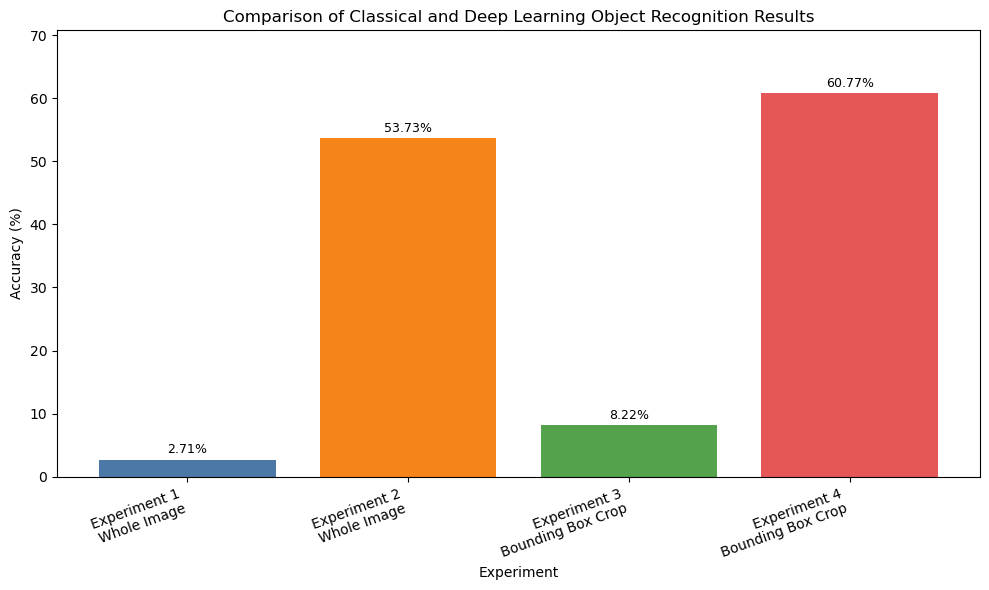

Saved final comparison plot to: .\outputs\final_four_experiments_accuracy_comparison.png


In [16]:
# Cell 14: Plot final comparison of all four experiments with four colours

plt.figure(figsize=(10, 6))

# Four colours for the four experiments
bar_colors = [
    "#4C78A8",  # Experiment 1 - blue
    "#F58518",  # Experiment 2 - orange
    "#54A24B",  # Experiment 3 - green
    "#E45756"   # Experiment 4 - red
]

x_labels = final_results["Experiment"] + "\n" + final_results["Input Type"]

bars = plt.bar(
    x_labels,
    final_results["Accuracy (%)"],
    color=bar_colors
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Experiment")
plt.title("Comparison of Classical and Deep Learning Object Recognition Results")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, max(final_results["Accuracy (%)"]) + 10)

# Add accuracy labels above bars
for i, value in enumerate(final_results["Accuracy (%)"]):
    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plot_path = os.path.join(
    OUTPUT_DIR,
    "final_four_experiments_accuracy_comparison.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved final comparison plot to:", plot_path)